<a href="https://colab.research.google.com/github/piaseckazaneta/Python/blob/main/STAC_API.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pystac-client planetary-computer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26/26 [planetary-computer]


In [4]:
import pystac_client
import planetary_computer

In [10]:
# 2. Otwarcie połączenia z katalogiem STAC:

# Wskazówka (ważne w Planetary Computer): Żeby później odczytywać pliki bez błędu autoryzacji, do metody .open() warto przekazać drugi parametr: modifier=planetary_computer.sign_inplace (automatycznie podpisuje darmowe tokeny dostępu do linków).
first_catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)

In [11]:
# 3. Zdefiniowanie zapytania (.search(...)):
result = first_catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=[20.9, 52.1, 21.1, 52.3],
    datetime="2026-07-01/2026-09-30",
    query={"eo:cloud_cover": {"lt": 10}}
)

In [13]:
# 4. Pobranie listy wyników i podgląd jednego zdjęcia:
items = result.item_collection()

In [14]:
# Sprawdzenie, ile scen zostało znalezionych
len(items)

26

In [15]:
item = items[0]

In [16]:
# Sprawdzenie daty pierwszego zdjęcia
item.datetime

datetime.datetime(2026, 9, 28, 9, 50, 31, 25000, tzinfo=tzutc())

In [17]:
# Sprawdzenie słownika dostępnych plików
item.assets.keys()

dict_keys(['AOT', 'B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B09', 'B11', 'B12', 'B8A', 'SCL', 'WVP', 'visual', 'safe-manifest', 'granule-metadata', 'inspire-metadata', 'product-metadata', 'datastrip-metadata', 'tilejson', 'rendered_preview'])

In [18]:
# Podejrzenie adresu URL pasma czerwonego:
# wskazuje on bezpośrednio na chmurę Azure (plik .tif w formacie COG), gotowy do użycia
item.assets['B04'].href

'https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/34/U/ED/2026/09/28/S2C_MSIL2A_20260928T095031_N0513_R079_T34UED_20260928T131313.SAFE/GRANULE/L2A_T34UED_A010774_20260928T095029/IMG_DATA/R10m/T34UED_20260928T095031_B04_10m.tif?st=2026-11-18T07%3A01%3A53Z&se=2026-11-19T07%3A46%3A53Z&sp=rl&sv=2025-07-05&sr=c&skoid=9c8ff44a-6a2c-4dfb-b298-1c9212f64d9a&sktid=72f988bf-86f1-41af-91ab-2d7cd011db47&skt=2026-11-19T07%3A00%3A24Z&ske=2026-11-26T07%3A00%3A24Z&sks=b&skv=2025-07-05&sig=XcxjmAad9d4b2aBIlN7XAfVlI8uPMebk30T6gM6k0V4%3D'

In [ ]:
# Najszybszy podgląd zdjęcia w 2 linijkach (bez pobierania całego rastra)
# Każdy element STAC z Planetary Computer posiada gotowy podgląd (rendered_preview)
# w formie małego pliku PNG. Możesz wyświetlić go bezpośrednio w komórce Colaba za pomocą wbudowanego modułu IPython.display

In [19]:
from IPython.display import Image

In [20]:
Image(url=item.assets["rendered_preview"].href)

In [21]:
# Podgląd konkretnego pasma w chmurze
# Jeśli chcę zobaczyć dane pomiarowe (np. pasmo czerwone "B04" lub kompozycję "visual") w układzie współrzędnych

!pip install -q rioxarray
import rioxarray

In [22]:
# Parametr overview_level=3 każe pobrać z chmury tylko warstwę piramidy o niższej rozdzielczości,
# dzięki czemu otworzy się w 1 sekundę zamiast pobierać 100 MB)
da = rioxarray.open_rasterio(item.assets["B04"].href, overview_level=3)

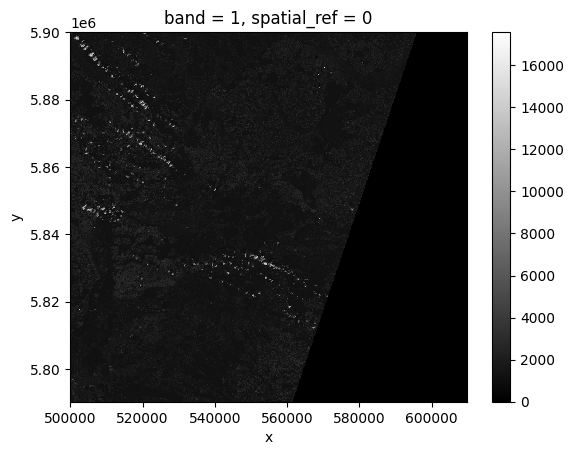

In [23]:
da.plot(cmap="gray")

COG - Cloud Optimized GeoTIFF

In [24]:
# Otwieranie dwóch osobnych obiektów (tym razem bez parametru overview_level, żeby mieć pełne 10 metrów rozdzielczości)
red = rioxarray.open_rasterio(item.assets["B04"].href)
nir = rioxarray.open_rasterio(item.assets["B08"].href)

# Wskazówka: Na tym etapie Python jeszcze nic nie pobrał — wczytał tylko metadane pliku z chmury (tzw. lazy loading)

In [26]:
# rzeczywisty zasięg wybranego zdjęcia
item.bbox

[20.9997003, 52.2563963, 22.4400344, 53.2496265]

In [27]:
# Wycięcie małego wycinka (clip_box) – kluczowy moment COG:
red_clip = red.rio.clip_box(minx=21.00, miny=52.42, maxx=21.12, maxy=52.50, crs="EPSG:4326")
nir_clip = nir.rio.clip_box(minx=21.00, miny=52.42, maxx=21.12, maxy=52.50, crs="EPSG:4326")

In [32]:
from contextlib import redirect_stderr
red_clip = red_clip.astype("float32")
nir_clip = nir_clip.astype("float32")

In [33]:
# Obliczenie wskaźnika NDVI (algebra macierzy):
NDVI = (nir_clip - red_clip) / (nir_clip + red_clip)

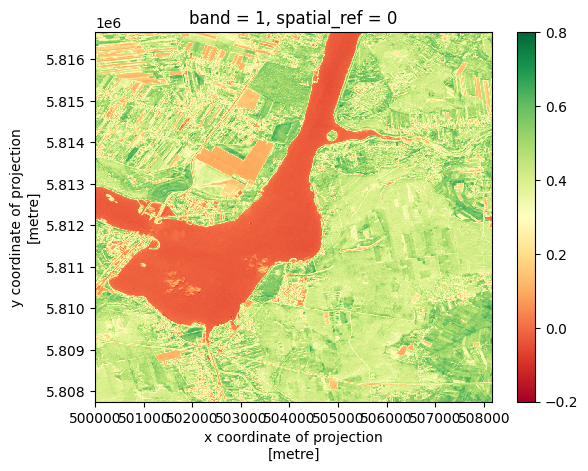

In [34]:
NDVI.plot(cmap="RdYlGn", vmin=-0.2, vmax=0.8)